# CSE 438

## Group Members

| Name | Student ID |
|------|------------|
| Sumiaya Sharif | 2023-1-60-048 |
| Ohiduzzaman Rayhan | 2023-1-60-108 |
| Prottoy Modak | 2022-3-60-130 |
| Afrina Alam Lamia | 2022-1-60-231 |

---

## Dataset

**Dataset Name:** FoodBD (FoodBD: A Polygon-Annotated Meal Image Dataset)

---

## Notebook

**NB0 — EDA & Data Preparation**

https://www.kaggle.com/code/sumiayasharif/nb0-eda-data-prep/edit/run/330790858

# Load NB0 artifacts + imports

In [1]:
import sys, os, time, json, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# SegFormer comes from Hugging Face Transformers, not torchvision
from transformers import SegformerForSemanticSegmentation

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [2]:
# ---- EDIT IF NEEDED ----
NB0_DATASET_SLUG = "/kaggle/input/datasets/shaheb366/rayhan888/nb0_artifacts"
# -------------------------

def _resolve(slug_or_path, suffix=""):
    base = slug_or_path if slug_or_path.startswith("/") else f"/kaggle/input/{slug_or_path}"
    return f"{base}/{suffix}" if suffix else base

CANDIDATE_DIRS = [
    _resolve(NB0_DATASET_SLUG),
    "/kaggle/working/nb0_artifacts",
]

ARTIFACT_DIR = None
for d in CANDIDATE_DIRS:
    if os.path.exists(os.path.join(d, "common_config.json")):
        ARTIFACT_DIR = d
        break

assert ARTIFACT_DIR is not None, (
    "Could not find NB0 artifacts in any candidate path:\n" + "\n".join(CANDIDATE_DIRS) +
    "\nRun `!ls -R /kaggle/input` to see what is actually mounted, then fix NB0_DATASET_SLUG above."
)
print("Using NB0 artifacts from:", ARTIFACT_DIR)

sys.path.insert(0, ARTIFACT_DIR)
from seg_common import (
    load_common_config, load_split_manifest,
    polygons_to_mask, get_transforms, FoodSegDataset
)

cfg = load_common_config(f"{ARTIFACT_DIR}/common_config.json")
split = load_split_manifest(f"{ARTIFACT_DIR}/split_manifest.json")

IMG_SIZE = cfg["img_size"]
NUM_CLASSES = cfg["num_classes_total"]
CLASS_NAMES = ["background"] + cfg["class_names"]
print(f"Num classes (incl. background): {NUM_CLASSES}")
print(f"Image size: {IMG_SIZE}")

# Show what path prefix is actually baked into split_manifest, so you can confirm it
# matches your attached raw dataset BEFORE hitting broken-symlink/imread errors later.
print("\nExample recorded image path:", split["train"][0])

Using NB0 artifacts from: /kaggle/input/datasets/shaheb366/rayhan888/nb0_artifacts
Num classes (incl. background): 68
Image size: 512

Example recorded image path: /kaggle/input/datasets/sumiayasharif/foodbd/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD/train/images/FoodBD-0002.jpg


In [3]:
# --- FAST FIX: split_manifest.json's image paths were recorded when NB0 ran, pointing at
# "sumiayasharif/foodbd". That copy of the dataset isn't attached to this session -- your
# copy lives under a different owner/slug ("shaheb366/new-data212"). Rather than re-running
# NB0, remap every path in split to point at YOUR attached raw dataset instead -- same
# underlying files/filenames, just a different mount prefix.

OLD_ROOT = "/kaggle/input/datasets/sumiayasharif/foodbd/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD"
NEW_ROOT = "/kaggle/input/datasets/shaheb366/new-data212/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD"

def _remap(p):
    return p.replace(OLD_ROOT, NEW_ROOT) if isinstance(p, str) else p

for key in ["train", "valid", "test"]:
    split[key] = [_remap(p) for p in split[key]]

print("Example remapped path:", split["train"][0])
assert os.path.exists(split["train"][0]), (
    "Remap still doesn't resolve -- run "
    "`!ls \"/kaggle/input/datasets/shaheb366/new-data212/FoodBD A Polygon-Annotated Meal Image Dataset of B/root\"` "
    "to see the actual folder name/casing under your dataset and fix NEW_ROOT above to match exactly."
)
print("Remap confirmed working -- paths now resolve to your attached dataset.")

Example remapped path: /kaggle/input/datasets/shaheb366/new-data212/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD/train/images/FoodBD-0002.jpg
Remap confirmed working -- paths now resolve to your attached dataset.


In [4]:
# Fail fast: confirm the RAW FoodBD image dataset is actually mounted in THIS session
# before building datasets/dataloaders. split only stores absolute image paths recorded
# when NB0 ran -- it does not carry the images themselves.
_sample_paths = (split["train"][:3] + split["valid"][:3] + split["test"][:3])
_missing = [p for p in _sample_paths if not os.path.exists(p)]

if _missing:
    print("RAW DATASET NOT FOUND at the paths recorded in split. Examples:")
    for p in _missing:
        print("  ", p)
    print("\nCurrently mounted under /kaggle/input:")
    for root, dirs, files in os.walk("/kaggle/input"):
        if files:
            print("  ", root, "->", len(files), "files, e.g.", files[0])
    raise FileNotFoundError(
        "Attach the raw FoodBD dataset at /kaggle/input/datasets/shaheb366/new-data212 "
        "(Add Input -> Datasets), or fix NEW_ROOT in the remap cell above to match the "
        "exact mounted path, then re-run this cell."
    )
else:
    print("Raw dataset confirmed mounted -- sample paths resolve correctly.")

Raw dataset confirmed mounted -- sample paths resolve correctly.


Datasets & Dataloaders (identical split + transforms as NB1, for a fair comparison)

In [5]:
train_transform = get_transforms(IMG_SIZE, train=True)
val_transform    = get_transforms(IMG_SIZE, train=False)

train_ds = FoodSegDataset(split["train"], train_transform, bg_is_zero=cfg["bg_is_zero"])
valid_ds = FoodSegDataset(split["valid"], val_transform,  bg_is_zero=cfg["bg_is_zero"])
test_ds  = FoodSegDataset(split["test"],  val_transform,  bg_is_zero=cfg["bg_is_zero"])

BATCH_SIZE = 8   # adjust down to 4 if you hit OOM on T4/P100 with IMG_SIZE=512

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True, drop_last=True)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train batches: {len(train_loader)}, Valid: {len(valid_loader)}, Test: {len(test_loader)}")

Train batches: 309, Valid: 88, Test: 45


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/kaggle/input/datasets/shaheb366/rayhan888/nb0_artifacts/seg_common.py:40: UserWarning: Argument(s) 'value, mask_value' are not valid for transform ShiftScaleRotate
  A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.15, rotate_limit=15, p=0.5,
/kaggle/input/datasets/shaheb366/rayhan888/nb0_artifacts/seg_common.py:45: UserWarning: Argument(s) 'max_holes, max_height, max_width, fill_value, mask_fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=4, max_height=32, max_width=32, fill_value=0, mask_fill_value=0, p=0.2),


Task E: Config cell (required — all hyperparameters visible in one place)

In [6]:
CONFIG = {
    "model": "SegFormer-B0",
    "backbone": "MiT-B0, ADE20K-pretrained @ 512x512 (nvidia/segformer-b0-finetuned-ade-512-512)",
    "num_classes": NUM_CLASSES,
    "input_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": 50,                     # minimum floor per instructions; extend if still improving
    "optimizer": "AdamW",
    "lr": 6e-5,                       # SegFormer's decoder/encoder are pretrained; lower LR than DeepLabV3's 1e-4
    "lr_schedule": "CosineAnnealingLR",
    "weight_decay": 1e-4,
    "loss_function": "Weighted CrossEntropy + Dice (combo)",
    "class_weighting": "inverse sqrt of pixel frequency (from NB0 pixel_class_distribution.csv)",
    "seed": SEED,
}
print(json.dumps(CONFIG, indent=2))

{
  "model": "SegFormer-B0",
  "backbone": "MiT-B0, ADE20K-pretrained @ 512x512 (nvidia/segformer-b0-finetuned-ade-512-512)",
  "num_classes": 68,
  "input_size": 512,
  "batch_size": 8,
  "epochs": 50,
  "optimizer": "AdamW",
  "lr": 6e-05,
  "lr_schedule": "CosineAnnealingLR",
  "weight_decay": 0.0001,
  "loss_function": "Weighted CrossEntropy + Dice (combo)",
  "class_weighting": "inverse sqrt of pixel frequency (from NB0 pixel_class_distribution.csv)",
  "seed": 42
}


Class weights (identical to NB1 — same imbalance fix, same NB0 source file)

In [7]:
dist_df = pd.read_csv(f"{ARTIFACT_DIR}/pixel_class_distribution.csv")
dist_df = dist_df.sort_values("class_id").reset_index(drop=True)

pixel_counts = dist_df["pixel_count"].values.astype(np.float64)
pixel_counts = np.clip(pixel_counts, 1, None)

inv_sqrt_freq = 1.0 / np.sqrt(pixel_counts)
class_weights = inv_sqrt_freq / inv_sqrt_freq.sum() * NUM_CLASSES
class_weights = np.clip(class_weights, 0.1, 10.0)
class_weights[0] *= 0.5

class_weights_t = torch.tensor(class_weights, dtype=torch.float32).to(device)
print("Class weight range:", class_weights.min(), "-", class_weights.max())

Class weight range: 0.05 - 2.340437993376195


Model setup — SegFormer-B0, ADE20K-pretrained encoder + decoder, head resized to our class count

`ignore_mismatched_sizes=True` drops ADE20K's 150-class classifier and re-initializes a fresh one for our classes; the MiT-B0 encoder and All-MLP decoder weights are kept.

In [8]:
id2label = {i: name for i, name in enumerate(CLASS_NAMES)}
label2id = {name: i for i, name in enumerate(CLASS_NAMES)}

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512",
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,   # replaces the 150-class ADE20K head with a fresh NUM_CLASSES head
)
model = model.to(device)
print(f"Total params: {sum(p.numel() for p in model.parameters())/1e6:.1f}M")

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/15.0M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                    
------------------------------+----------+----------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150]) vs model:torch.Size([68])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([68, 256, 1, 1])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


Total params: 3.7M


Loss function (weighted CE + Dice combo, same recipe as NB1)

SegFormer's decoder outputs logits at 1/4 input resolution (128x128 for a 512 input), so they must be upsampled back to the mask's full resolution before computing any pixel-wise loss or metric.

In [9]:
def dice_loss(logits, targets, num_classes, eps=1e-6):
    probs = F.softmax(logits, dim=1)
    targets_onehot = F.one_hot(targets, num_classes).permute(0, 3, 1, 2).float()
    dims = (0, 2, 3)
    intersection = torch.sum(probs * targets_onehot, dims)
    union = torch.sum(probs + targets_onehot, dims)
    dice = (2 * intersection + eps) / (union + eps)
    return 1 - dice.mean()

ce_loss_fn = nn.CrossEntropyLoss(weight=class_weights_t)

def get_upsampled_logits(outputs, target_hw):
    # outputs.logits: (B, NUM_CLASSES, H/4, W/4) -> upsample to (B, NUM_CLASSES, H, W)
    return F.interpolate(outputs.logits, size=target_hw, mode="bilinear", align_corners=False)

def combo_loss(logits, targets):
    ce = ce_loss_fn(logits, targets)
    dl = dice_loss(logits, targets, NUM_CLASSES)
    return 0.6 * ce + 0.4 * dl

mIoU metric helper (used for validation monitoring — identical to NB1 for comparability)

In [10]:
def compute_miou(conf_mat, num_classes):
    ious = []
    for c in range(num_classes):
        tp = conf_mat[c, c]
        fp = conf_mat[:, c].sum() - tp
        fn = conf_mat[c, :].sum() - tp
        denom = tp + fp + fn
        ious.append(tp / denom if denom > 0 else np.nan)
    return np.nanmean(ious), ious

def update_confusion(conf_mat, preds, targets, num_classes):
    p = preds.flatten().cpu().numpy()
    t = targets.flatten().cpu().numpy()
    mask = (t >= 0) & (t < num_classes)
    conf_mat += np.bincount(
        num_classes * t[mask].astype(int) + p[mask].astype(int),
        minlength=num_classes**2
    ).reshape(num_classes, num_classes)
    return conf_mat

Training loop (≥50 epochs, extend if still improving)

In [11]:
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["epochs"])
scaler = torch.cuda.amp.GradScaler()

MIN_EPOCHS = 50
best_val_miou = -1.0
best_epoch = 0
patience_extend = 5     # epochs of continued improvement allowed past the floor before stopping
history = {"train_loss": [], "val_loss": [], "val_miou": []}

start_time = time.time()
epoch = 0
no_improve_streak = 0

while True:
    epoch += 1
    model.train()
    running_loss = 0.0
    for imgs, masks in train_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            outputs = model(pixel_values=imgs)
            logits = get_upsampled_logits(outputs, masks.shape[-2:])
            loss = combo_loss(logits, masks)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item()
    train_loss = running_loss / len(train_loader)
    scheduler.step()

    # Validation
    model.eval()
    val_loss = 0.0
    conf_mat = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    with torch.no_grad():
        for imgs, masks in valid_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            outputs = model(pixel_values=imgs)
            logits = get_upsampled_logits(outputs, masks.shape[-2:])
            loss = ce_loss_fn(logits, masks)
            val_loss += loss.item()
            preds = logits.argmax(1)
            conf_mat = update_confusion(conf_mat, preds, masks, NUM_CLASSES)
    val_loss /= len(valid_loader)
    val_miou, _ = compute_miou(conf_mat, NUM_CLASSES)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_miou"].append(val_miou)

    print(f"Epoch {epoch:03d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_mIoU={val_miou:.4f}")

    improved = val_miou > best_val_miou
    if improved:
        best_val_miou = val_miou
        best_epoch = epoch
        no_improve_streak = 0
        torch.save(model.state_dict(), "segformer_best.pth")
    else:
        no_improve_streak += 1

    # Stop once we've cleared the epoch floor AND stopped improving for `patience_extend` epochs
    if epoch >= MIN_EPOCHS and no_improve_streak >= patience_extend:
        print(f"Stopping at epoch {epoch}. Best val mIoU={best_val_miou:.4f} at epoch {best_epoch}.")
        break

elapsed = time.time() - start_time
print(f"Training took {elapsed/60:.1f} minutes over {epoch} epochs.")

/tmp/ipykernel_22/4001290321.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_22/4001290321.py:22: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 001 | train_loss=2.3473 | val_loss=2.3121 | val_mIoU=0.1135
Epoch 002 | train_loss=1.7083 | val_loss=1.7101 | val_mIoU=0.1404
Epoch 003 | train_loss=1.4108 | val_loss=1.4287 | val_mIoU=0.2057
Epoch 004 | train_loss=1.2314 | val_loss=1.1928 | val_mIoU=0.2681
Epoch 005 | train_loss=1.1003 | val_loss=1.0906 | val_mIoU=0.2835
Epoch 006 | train_loss=1.0062 | val_loss=0.9779 | val_mIoU=0.3275
Epoch 007 | train_loss=0.9405 | val_loss=0.9107 | val_mIoU=0.3464
Epoch 008 | train_loss=0.8867 | val_loss=0.8641 | val_mIoU=0.3721
Epoch 009 | train_loss=0.8376 | val_loss=0.8129 | val_mIoU=0.4048
Epoch 010 | train_loss=0.8097 | val_loss=0.7939 | val_mIoU=0.4113
Epoch 011 | train_loss=0.7548 | val_loss=0.7893 | val_mIoU=0.4181
Epoch 012 | train_loss=0.7314 | val_loss=0.7539 | val_mIoU=0.4198
Epoch 013 | train_loss=0.7019 | val_loss=0.7804 | val_mIoU=0.4122
Epoch 014 | train_loss=0.6922 | val_loss=0.7246 | val_mIoU=0.4367
Epoch 015 | train_loss=0.6643 | val_loss=0.7089 | val_mIoU=0.4459
Epoch 016 

Training curves

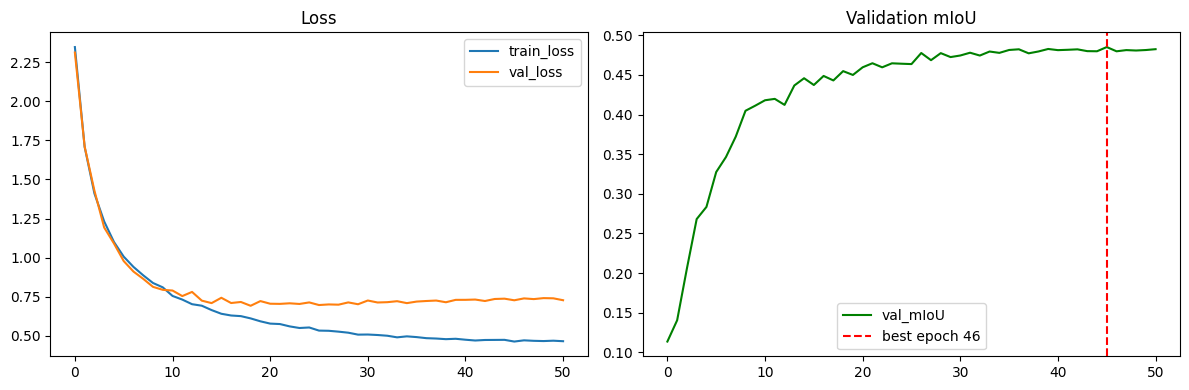

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], label="train_loss")
axes[0].plot(history["val_loss"], label="val_loss")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(history["val_miou"], label="val_mIoU", color="green")
axes[1].axvline(best_epoch-1, color="red", linestyle="--", label=f"best epoch {best_epoch}")
axes[1].set_title("Validation mIoU"); axes[1].legend()
plt.tight_layout()
plt.savefig("segformer_training_curves.png", dpi=150)
plt.show()

Task F: Load best checkpoint, evaluate on held-out TEST split

In [13]:
model.load_state_dict(torch.load("segformer_best.pth"))
model.eval()

conf_mat_test = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
per_image_ious = []  # (index, iou) for Task G worst-case analysis

with torch.no_grad():
    for batch_idx, (imgs, masks) in enumerate(test_loader):
        imgs, masks = imgs.to(device), masks.to(device)
        outputs = model(pixel_values=imgs)
        logits = get_upsampled_logits(outputs, masks.shape[-2:])
        preds = logits.argmax(1)
        conf_mat_test = update_confusion(conf_mat_test, preds, masks, NUM_CLASSES)

        for i in range(imgs.size(0)):
            p, t = preds[i], masks[i]
            classes_present = torch.unique(t)
            ious = []
            for c in classes_present:
                c = c.item()
                if c == 0:  # skip background for per-image "worst" ranking
                    continue
                tp = ((p == c) & (t == c)).sum().item()
                fp_fn = ((p == c) | (t == c)).sum().item()
                if fp_fn > 0:
                    ious.append(tp / fp_fn)
            img_iou = np.mean(ious) if ious else np.nan
            global_idx = batch_idx * BATCH_SIZE + i
            per_image_ious.append((global_idx, img_iou))

# Metrics
miou_test, per_class_iou = compute_miou(conf_mat_test, NUM_CLASSES)
pixel_acc = np.trace(conf_mat_test) / conf_mat_test.sum()
per_class_acc = [conf_mat_test[c,c] / conf_mat_test[c,:].sum() if conf_mat_test[c,:].sum()>0 else np.nan
                  for c in range(NUM_CLASSES)]
mean_pixel_acc = np.nanmean(per_class_acc)

def dice_from_conf(conf_mat, num_classes):
    dices = []
    for c in range(num_classes):
        tp = conf_mat[c,c]
        fp = conf_mat[:,c].sum() - tp
        fn = conf_mat[c,:].sum() - tp
        denom = 2*tp + fp + fn
        dices.append(2*tp/denom if denom>0 else np.nan)
    return dices

per_class_dice = dice_from_conf(conf_mat_test, NUM_CLASSES)

print(f"Test mIoU:        {miou_test:.4f}")
print(f"Test Pixel Acc:   {pixel_acc:.4f}")
print(f"Test Mean PixAcc: {mean_pixel_acc:.4f}")
print(f"Best epoch:       {best_epoch} (val mIoU={best_val_miou:.4f})")

Test mIoU:        0.4800
Test Pixel Acc:   0.9344
Test Mean PixAcc: 0.6943
Best epoch:       46 (val mIoU=0.4852)


In [14]:
results_df = pd.DataFrame({
    "class_id": range(NUM_CLASSES),
    "class_name": CLASS_NAMES,
    "IoU": per_class_iou,
    "PixelAcc": per_class_acc,
    "Dice": per_class_dice,
})
results_df.to_csv("segformer_test_metrics_per_class.csv", index=False)

test_summary = {
    "model": CONFIG["model"],
    "backbone": CONFIG["backbone"],
    "test_mIoU": float(miou_test),
    "test_pixel_acc": float(pixel_acc),
    "test_mean_pixel_acc": float(mean_pixel_acc),
    "best_epoch": best_epoch,
    "best_val_mIoU": float(best_val_miou),
    "total_epochs_trained": epoch,
    "num_params_millions": round(sum(p.numel() for p in model.parameters()) / 1e6, 2),
}
with open("segformer_test_summary.json", "w") as f:
    json.dump(test_summary, f, indent=2)

print(json.dumps(test_summary, indent=2))
results_df.sort_values("IoU").head(10)

{
  "model": "SegFormer-B0",
  "backbone": "MiT-B0, ADE20K-pretrained @ 512x512 (nvidia/segformer-b0-finetuned-ade-512-512)",
  "test_mIoU": 0.4800178820641928,
  "test_pixel_acc": 0.9344382353612452,
  "test_mean_pixel_acc": 0.6943425992095607,
  "best_epoch": 46,
  "best_val_mIoU": 0.4852278167992777,
  "total_epochs_trained": 51,
  "num_params_millions": 3.73
}


,class_id,class_name,IoU,PixelAcc,Dice
24,24,egg,0.000000,NaN,0.000000
18,18,chomchom,0.000000,0.000000,0.000000
62,62,sweets,0.015582,0.025821,0.030686
57,57,roll,0.025169,0.099492,0.049103
2,2,apple,0.084058,0.340136,0.155081
11,11,cabbage,0.095895,0.177732,0.175007
33,33,kabab,0.100711,0.256886,0.182993
15,15,chichinga-vaji,0.103203,0.240195,0.187097
1,1,achar,0.118786,0.190004,0.212348
30,30,guava,0.137507,0.139905,0.241769


Confusion matrix visualization

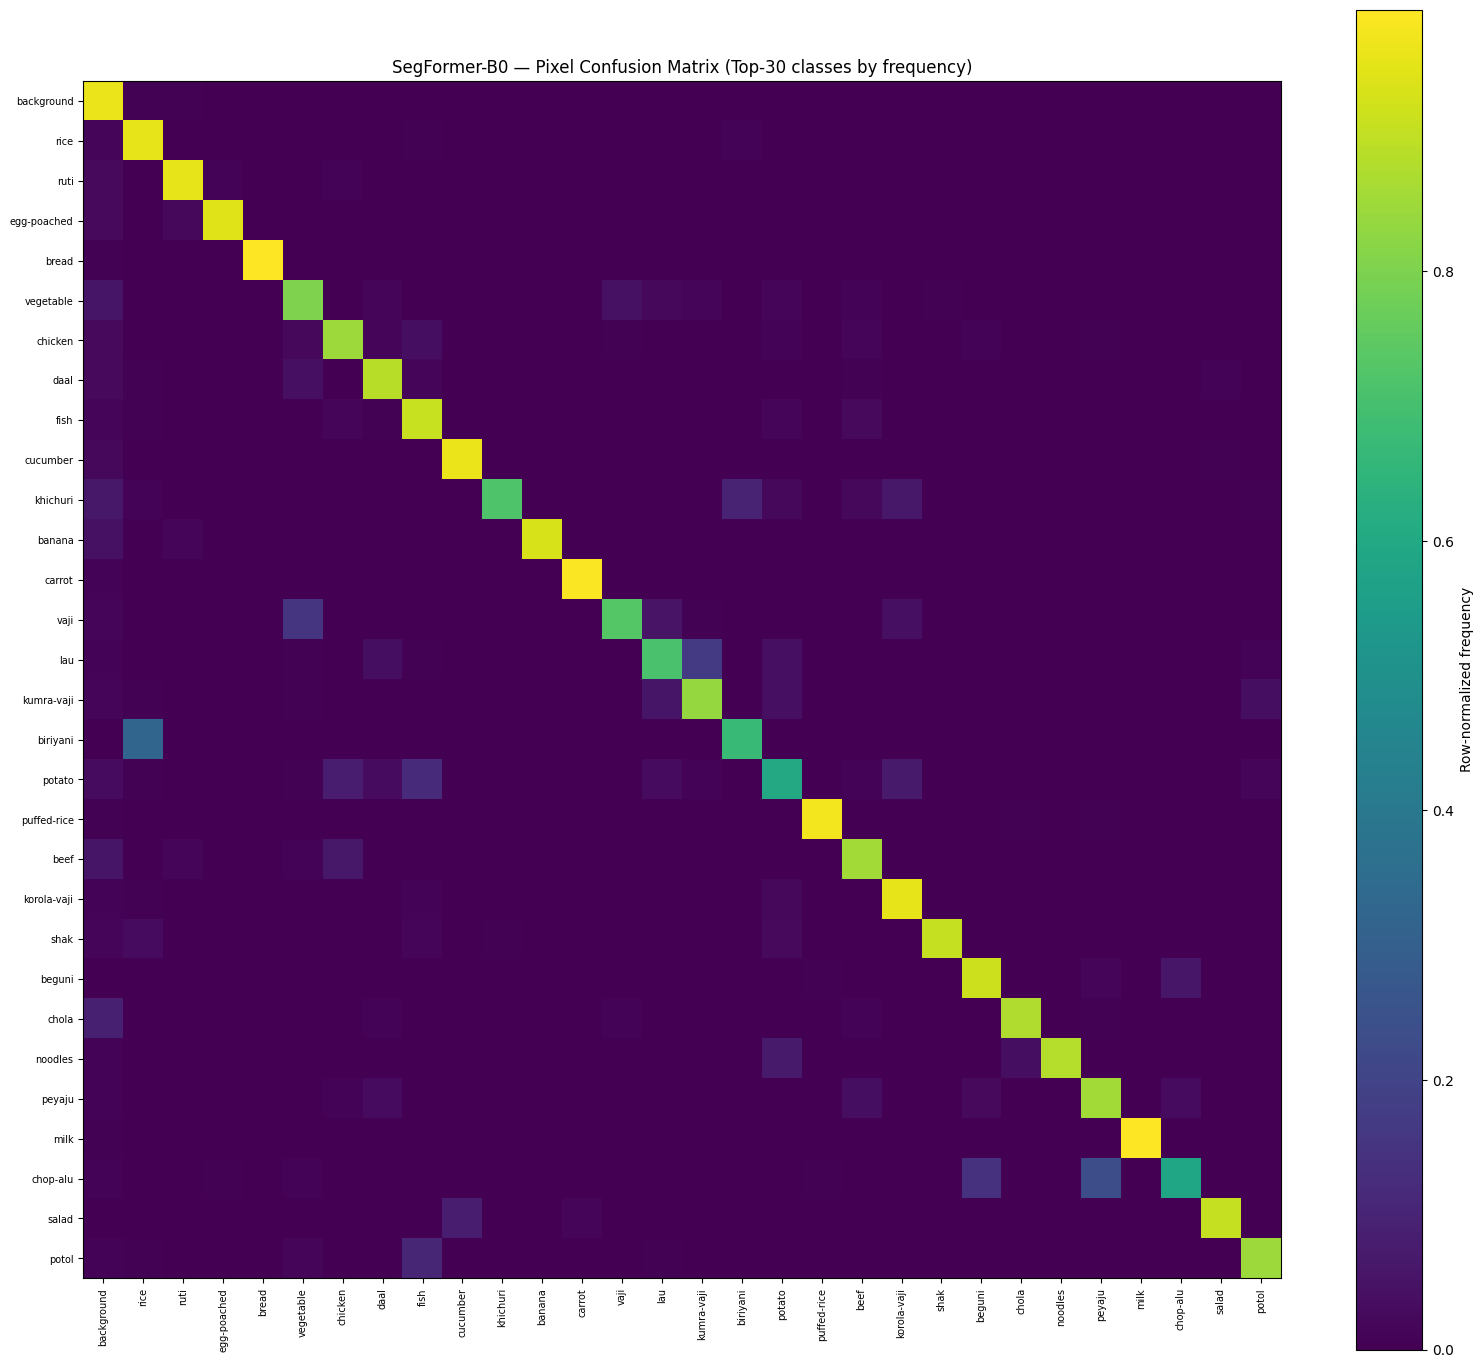

In [15]:
plt.figure(figsize=(16,14))
# Normalize per-row for readability, only show top-30 most frequent classes to keep it legible
top_classes = dist_df.sort_values("pixel_count", ascending=False)["class_id"].values[:30]
sub_conf = conf_mat_test[np.ix_(top_classes, top_classes)]
sub_conf_norm = sub_conf / (sub_conf.sum(axis=1, keepdims=True) + 1e-9)

plt.imshow(sub_conf_norm, cmap="viridis")
plt.colorbar(label="Row-normalized frequency")
plt.xticks(range(len(top_classes)), [CLASS_NAMES[c] for c in top_classes], rotation=90, fontsize=7)
plt.yticks(range(len(top_classes)), [CLASS_NAMES[c] for c in top_classes], fontsize=7)
plt.title("SegFormer-B0 — Pixel Confusion Matrix (Top-30 classes by frequency)")
plt.tight_layout()
plt.savefig("segformer_confusion_matrix.png", dpi=150)
plt.show()

Task G: Error Analysis — worst-performing test images

Worst 5 test images (by mean per-image IoU, excluding background):
  idx=152, IoU=0.0000
  idx=308, IoU=0.0000
  idx=181, IoU=0.0051
  idx=192, IoU=0.0218
  idx=198, IoU=0.0310


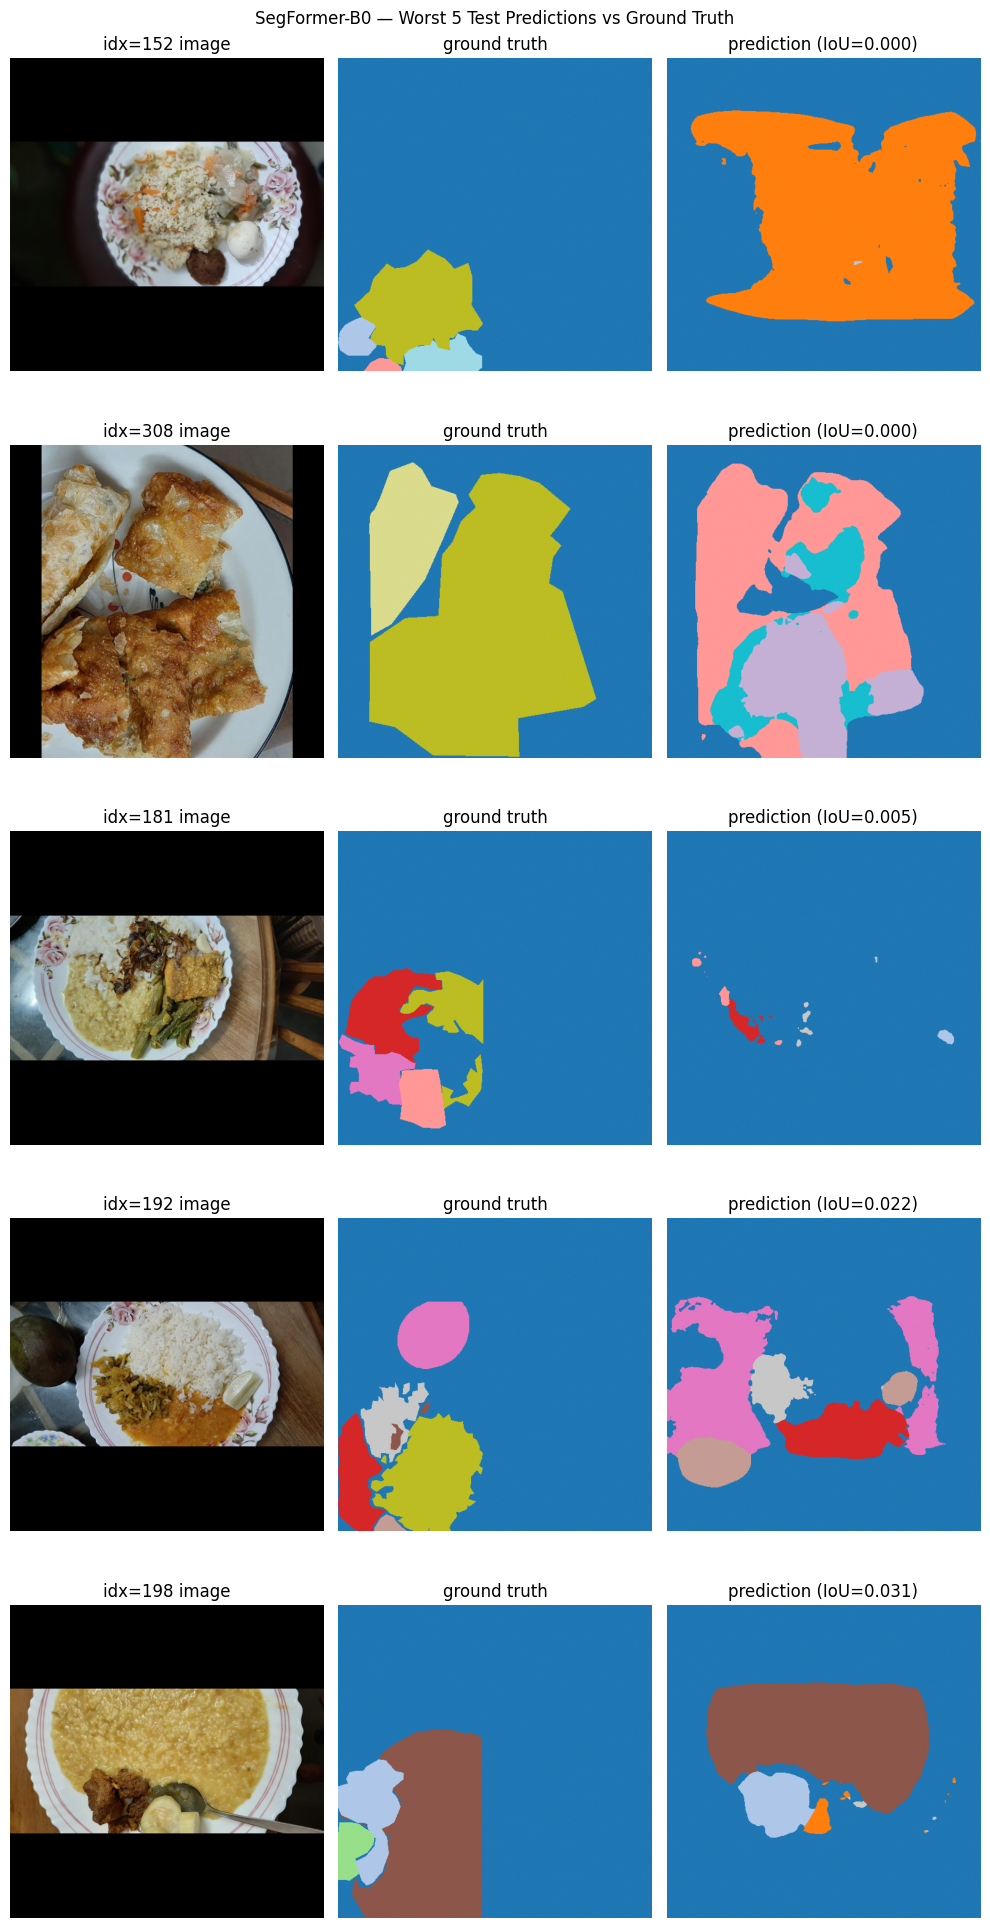

In [16]:
per_image_ious_sorted = sorted(per_image_ious, key=lambda x: (np.nan if np.isnan(x[1]) else x[1]))
worst_5 = [x for x in per_image_ious_sorted if not np.isnan(x[1])][:5]
print("Worst 5 test images (by mean per-image IoU, excluding background):")
for idx, iou in worst_5:
    print(f"  idx={idx}, IoU={iou:.4f}")

def get_test_image_mask(idx):
    img_t, mask_t = test_ds[idx]
    return img_t, mask_t

def denorm(img_t):
    mean = np.array([0.485,0.456,0.406]).reshape(3,1,1)
    std  = np.array([0.229,0.224,0.225]).reshape(3,1,1)
    img = img_t.numpy()*std + mean
    return np.clip(img.transpose(1,2,0), 0, 1)

fig, axes = plt.subplots(len(worst_5), 3, figsize=(10, 4*len(worst_5)))
model.eval()
with torch.no_grad():
    for row, (idx, iou) in enumerate(worst_5):
        img_t, mask_t = get_test_image_mask(idx)
        outputs = model(pixel_values=img_t.unsqueeze(0).to(device))
        logits = get_upsampled_logits(outputs, mask_t.shape[-2:])
        pred = logits.argmax(1).squeeze(0).cpu().numpy()

        img_np = denorm(img_t)
        axes[row,0].imshow(img_np); axes[row,0].set_title(f"idx={idx} image"); axes[row,0].axis("off")
        axes[row,1].imshow(mask_t.numpy(), cmap="tab20", vmin=0, vmax=NUM_CLASSES); axes[row,1].set_title("ground truth"); axes[row,1].axis("off")
        axes[row,2].imshow(pred, cmap="tab20", vmin=0, vmax=NUM_CLASSES); axes[row,2].set_title(f"prediction (IoU={iou:.3f})"); axes[row,2].axis("off")

plt.suptitle("SegFormer-B0 — Worst 5 Test Predictions vs Ground Truth")
plt.tight_layout()
plt.savefig("segformer_worst_predictions.png", dpi=150)
plt.show()

# Save worst indices for cross-model comparison in NB3's Task H (do same images fail across models?)
worst_indices = [idx for idx, _ in worst_5]
with open("segformer_worst_indices.json", "w") as f:
    json.dump(worst_indices, f)

Most confused class pairs

In [17]:
conf_no_bg = conf_mat_test.copy()
np.fill_diagonal(conf_no_bg, 0)
conf_no_bg[0,:] = 0; conf_no_bg[:,0] = 0  # exclude background from "confusion" analysis

flat_indices = np.dstack(np.unravel_index(np.argsort(-conf_no_bg.ravel()), conf_no_bg.shape))[0]
print("Top 10 most confused class pairs (true -> predicted):")
seen_pairs = set()
count = 0
for t, p in flat_indices:
    if t == p or conf_no_bg[t,p] == 0:
        continue
    pair_key = tuple(sorted((t,p)))
    if pair_key in seen_pairs:
        continue
    seen_pairs.add(pair_key)
    print(f"  {CLASS_NAMES[t]} <-> {CLASS_NAMES[p]}: {conf_no_bg[t,p] + conf_no_bg[p,t]} pixels")
    count += 1
    if count >= 10:
        break

Top 10 most confused class pairs (true -> predicted):
  guava <-> vegetable: 70513 pixels
  rice <-> biriyani: 104815 pixels
  lau <-> kumra-vaji: 81421 pixels
  vaji <-> vegetable: 93672 pixels
  shak <-> lal-shak: 48052 pixels
  khichuri <-> biriyani: 46839 pixels
  cauliflower <-> vegetable: 57595 pixels
  puri <-> egg-poached: 43814 pixels
  daal <-> vegetable: 53788 pixels
  chop-alu <-> peyaju: 44167 pixels


Save NB2 outputs for NB3's Task H comparison

In [18]:
import shutil
os.makedirs("/kaggle/working/nb2_outputs", exist_ok=True)
for f in ["segformer_test_summary.json", "segformer_test_metrics_per_class.csv",
          "segformer_worst_indices.json", "segformer_best.pth",
          "segformer_training_curves.png", "segformer_confusion_matrix.png",
          "segformer_worst_predictions.png"]:
    shutil.copy(f, f"/kaggle/working/nb2_outputs/{f}")

print("NB2 outputs saved — publish this notebook's output as a dataset (e.g. 'food-seg-nb2-segformer-outputs') so NB3 can pull these metrics for the final comparison.")

NB2 outputs saved — publish this notebook's output as a dataset (e.g. 'food-seg-nb2-segformer-outputs') so NB3 can pull these metrics for the final comparison.


In [19]:
import shutil
from IPython.display import FileLink, display

zip_path = shutil.make_archive(
    "/kaggle/working/nb2_segformer_outputs",  # produces nb2_segformer_outputs.zip
    "zip",
    "/kaggle/working/nb2_outputs"
)
print("Zipped outputs to:", zip_path)
print(f"Size: {os.path.getsize(zip_path) / 1e6:.1f} MB")

# Click this link to download directly from the running session
display(FileLink(zip_path))

Zipped outputs to: /kaggle/working/nb2_segformer_outputs.zip
Size: 16.8 MB


/kaggle/working/nb2_segformer_outputs.zip